# **TEXT ANALYSIS**

**MODULES**

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing
pd.options.mode.chained_assignment = None

#-- IF YOU USE THEN USE THE BELOW LINE --
# import os #File location
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

from wordcloud import WordCloud #Word visualization
import matplotlib.pyplot as plt #Plotting properties
import seaborn as sns #Plotting properties
from sklearn.feature_extraction.text import CountVectorizer #Data transformation
from sklearn.model_selection import train_test_split #Data testing
from sklearn.linear_model import LogisticRegression #Prediction Model
from sklearn.metrics import accuracy_score #Comparison between real and predicted
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder #Variable encoding and decoding for XGBoost
import re #Regular expressions
import nltk
from nltk import word_tokenize
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
#-- FOR CHECKING PROPOSE
import nltk
from nltk.tokenize import word_tokenize

# Download the required dataset inside Colab
nltk.download('punkt_tab')

# Test text
text = "Google Colab makes NLP easy, doesn't it?"
tokens = word_tokenize(text)

print(tokens)


['Google', 'Colab', 'makes', 'NLP', 'easy', ',', 'does', "n't", 'it', '?']


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


**DATA IMPORT**

In [ ]:
#-- IF YOU USE GOOGLE COLAB --
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train = pd.read_csv("/content/drive/MyDrive/Datasets/Twitter/twitter_training.csv")
valid = pd.read_csv("/content/drive/MyDrive/Datasets/Twitter/twitter_validation.csv")

**Saaf Safai**

In [ ]:
train.columns = ['id','information','type','comments']
valid.columns = ['id','information','type','comments']

In [ ]:
train.head()

,id,information,type,comments
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [ ]:
valid.head()

,id,information,type,comments
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74681 entries, 0 to 74680
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           74681 non-null  int64 
 1   information  74681 non-null  object
 2   type         74681 non-null  object
 3   comments     73995 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB


In [ ]:
valid.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           999 non-null    int64 
 1   information  999 non-null    object
 2   type         999 non-null    object
 3   comments     999 non-null    object
dtypes: int64(1), object(3)
memory usage: 31.3+ KB


In [ ]:
valid.isnull().sum()

,0
id,0
information,0
type,0
comments,0


In [ ]:
train.isnull().sum()

,0
id,0
information,0
type,0
comments,0


In [ ]:
train.dropna(subset=["comments"], inplace=True)
train.reset_index(drop=True, inplace=True)

In [ ]:
train.duplicated().sum()

np.int64(2340)

In [ ]:
train[train.duplicated()]


,id,information,type,comments
19,2404,Borderlands,Positive,that was the first borderlands session in a lo...
25,2405,Borderlands,Negative,The biggest disappointment of my life came a y...
50,2409,Borderlands,Neutral,Blaming Sight for Tardiness! A little bit of b...
62,2411,Borderlands,Neutral,.. [
144,2425,Borderlands,Negative,"""What a bitch!"""
...,...,...,...,...
73818,9171,Nvidia,Neutral,This benchmarking comparison between Oculus Qu...
73823,9172,Nvidia,Positive,@ NVIDIAGeForce @ nvidia
73902,9185,Nvidia,Neutral,Heard people are having issues with ordering t...
73932,9190,Nvidia,Positive,This news about the Nvidia 3000 series is ligi...


In [ ]:
train["lower"] = train.comments.str.lower()
train["lower"] = [str(data)for data in train.lower]
train["lower"] = train.lower.apply(
    lambda x: re.sub('[^A-Za-z0-9 ]+', ' ', x)
)
train.head(10)

,id,information,type,comments,lower
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...,im getting into borderlands and i can murder y...
5,2402,Borderlands,Positive,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...
6,2402,Borderlands,Positive,So I spent a couple of hours doing something f...,so i spent a couple of hours doing something f...
7,2402,Borderlands,Positive,So I spent a few hours doing something for fun...,so i spent a few hours doing something for fun...
8,2402,Borderlands,Positive,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...
9,2402,Borderlands,Positive,2010 So I spent a few hours making something f...,2010 so i spent a few hours making something f...


In [ ]:
valid["lower"] = valid.comments.str.lower()
valid["lower"] = [str(data)for data in valid.lower]
valid["lower"] = valid.lower.apply(
    lambda x: re.sub('[^A-Za-z0-9 ]+', ' ', x)
)
valid.head(10)

,id,information,type,comments,lower
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...,bbc news amazon boss jeff bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...,microsoft why do i pay for word when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,...",csgo matchmaking is so full of closet hacking ...
3,4433,Google,Neutral,Now the President is slapping Americans in the...,now the president is slapping americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...,hi eahelp i ve had madeleine mccann in my cel...
5,7925,MaddenNFL,Positive,Thank you @EAMaddenNFL!! \n\nNew TE Austin Hoo...,thank you eamaddennfl new te austin hooper ...
6,11332,TomClancysRainbowSix,Positive,"Rocket League, Sea of Thieves or Rainbow Six: ...",rocket league sea of thieves or rainbow six ...
7,1107,AssassinsCreed,Positive,my ass still knee-deep in Assassins Creed Odys...,my ass still knee deep in assassins creed odys...
8,2069,CallOfDuty,Negative,FIX IT JESUS ! Please FIX IT ! What In the wor...,fix it jesus please fix it what in the wor...
9,3185,Dota2,Positive,The professional dota 2 scene is fucking explo...,the professional dota 2 scene is fucking explo...


In [ ]:
train.isnull().sum()

,0
id,0
information,0
type,0
comments,0
lower,0


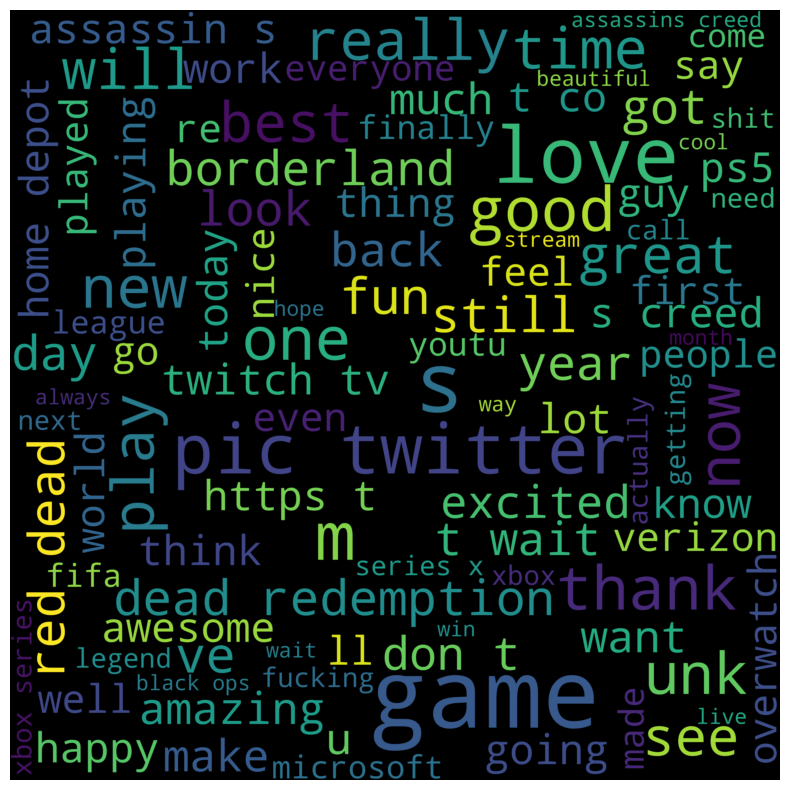

In [ ]:
word_cloud_text = ''.join(train[train["type"]=="Positive"].lower)
#Creation of wordcloud
wordcloud = WordCloud(
    max_font_size=100,
    max_words=100,
    background_color="black",
    scale=10,
    width=800,
    height=800
).generate(word_cloud_text)
#Figure properties
plt.figure(figsize=(10,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

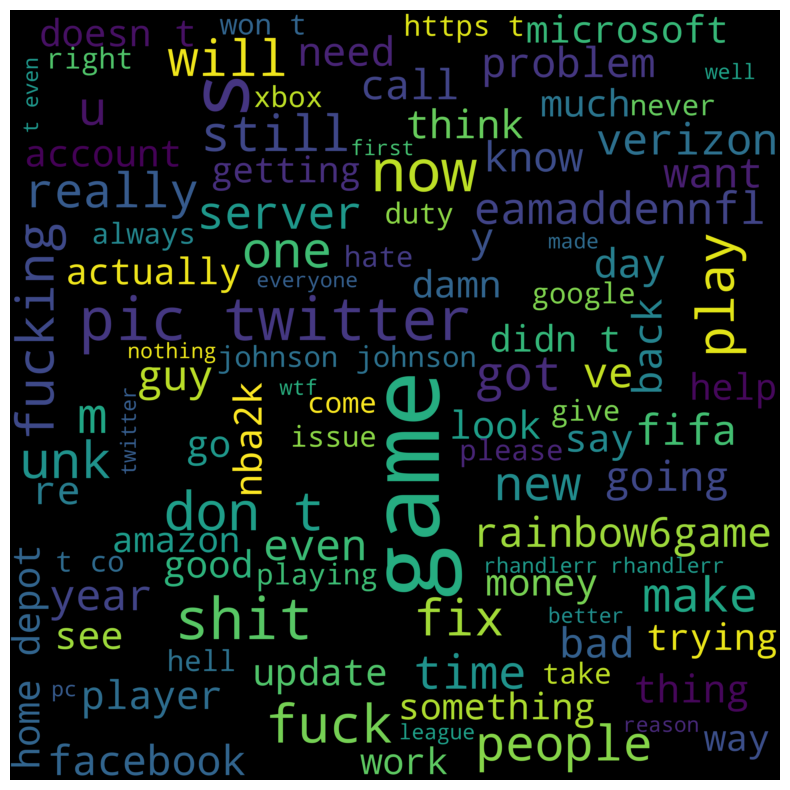

In [ ]:
word_cloud_text = ''.join(train[train["type"]=="Negative"].lower)
#Creation of wordcloud
wordcloud = WordCloud(
    max_font_size=100,
    max_words=100,
    background_color="black",
    scale=10,
    width=800,
    height=800
).generate(word_cloud_text)
#Figure properties
plt.figure(figsize=(10,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

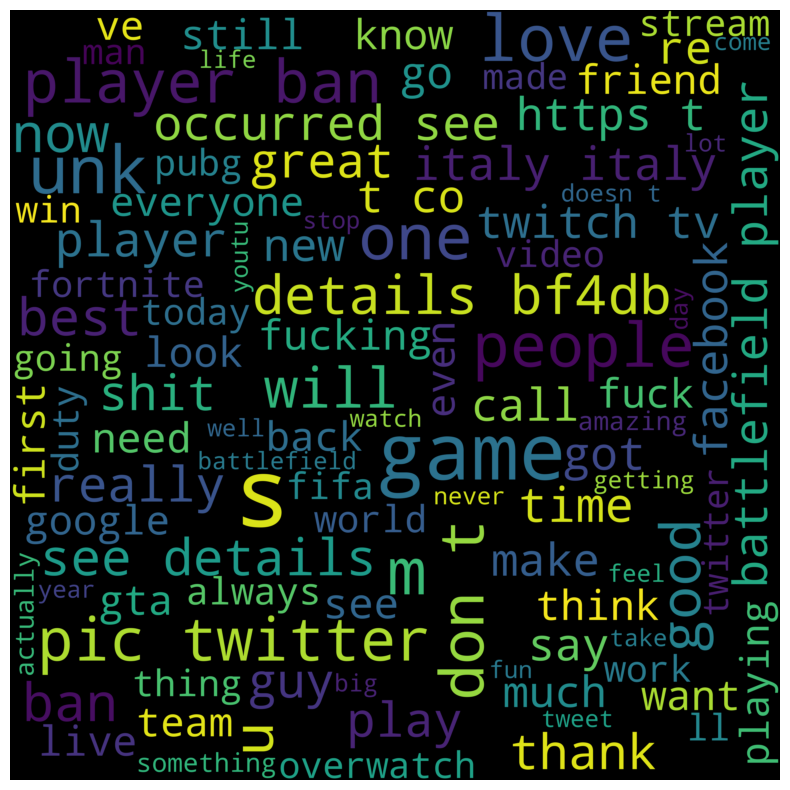

In [ ]:
word_cloud_text = ''.join(train[train["type"]=="Irrelevant"].lower)
#Creation of wordcloud
wordcloud = WordCloud(
    max_font_size=100,
    max_words=100,
    background_color="black",
    scale=10,
    width=800,
    height=800
).generate(word_cloud_text)
#Figure properties
plt.figure(figsize=(10,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

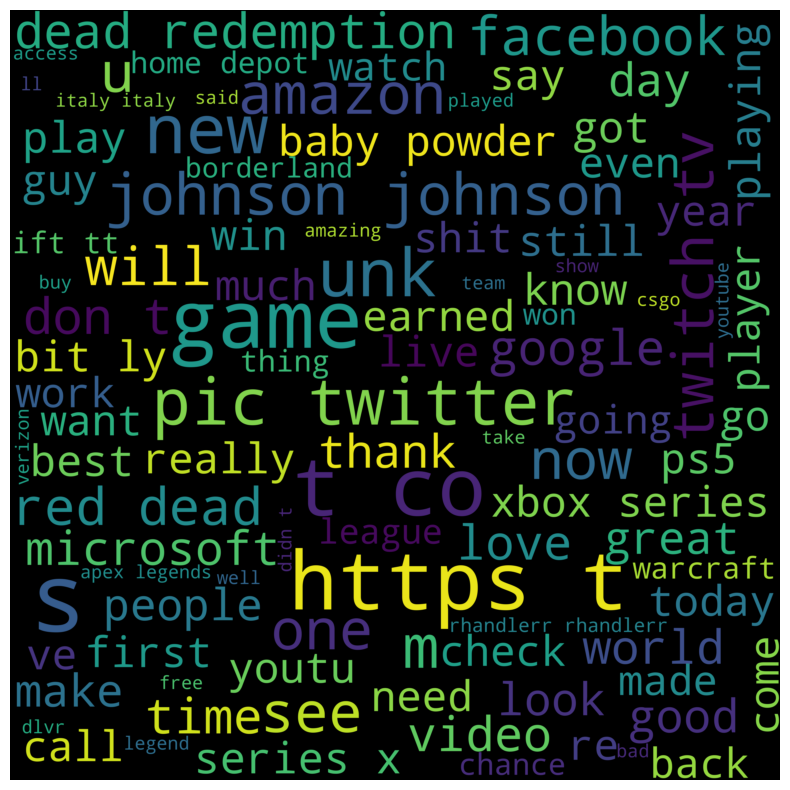

In [ ]:
word_cloud_text = ''.join(train[train["type"]=="Neutral"].lower)
#Creation of wordcloud
wordcloud = WordCloud(
    max_font_size=100,
    max_words=100,
    background_color="black",
    scale=10,
    width=800,
    height=800
).generate(word_cloud_text)
#Figure properties
plt.figure(figsize=(10,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [ ]:
plot1=train.groupby(by=["information","type"]).count().reset_index()
plot1.head()

,information,type,id,comments,lower
0,Amazon,Irrelevant,186,186,186
1,Amazon,Negative,575,575,575
2,Amazon,Neutral,1207,1207,1207
3,Amazon,Positive,308,308,308
4,ApexLegends,Irrelevant,192,192,192


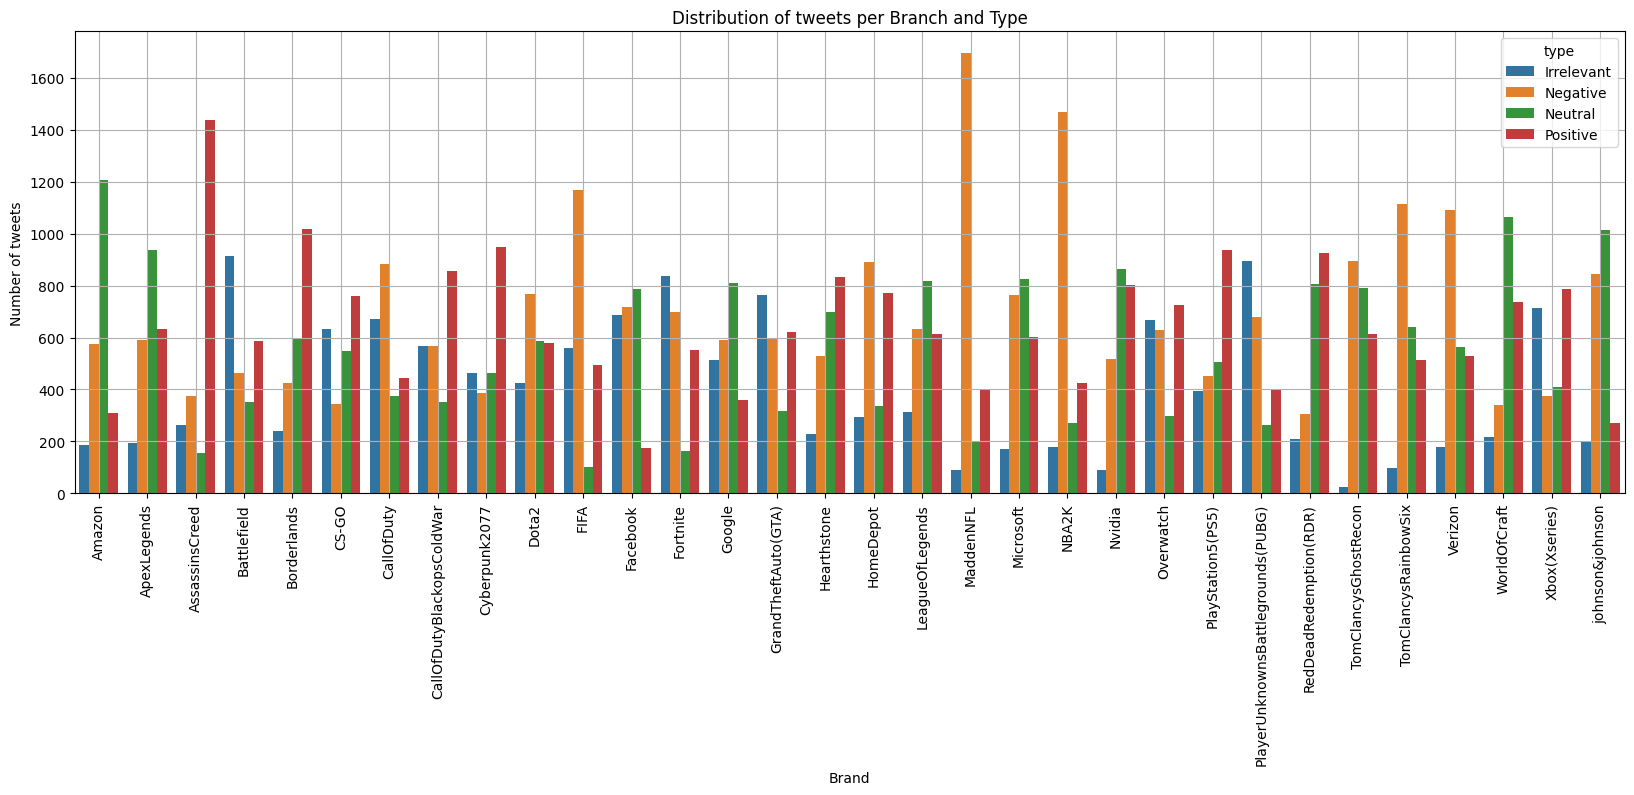

In [ ]:
#Figure of comparison per branch
plt.figure(figsize=(20,6))
sns.barplot(data=plot1,x="information",y="id",hue="type")
plt.xticks(rotation=90)
plt.xlabel("Brand")
plt.ylabel("Number of tweets")
plt.grid()
plt.title("Distribution of tweets per Branch and Type");

In [ ]:
tokens_text = [word_tokenize(str(word)) for word in train.lower]
tokens_counter = [item for sublist in tokens_text for item in sublist]
print("Number of tokens: ", len(set(tokens_counter)))

Number of tokens:  30435


In [ ]:
tokens_text[100]

['appreciate',
 'the',
 'sonic',
 'concepts',
 'praxis',
 'valenzuela',
 'and',
 'landa',
 'posas',
 'thread',
 'together',
 'in',
 'this',
 'talk',
 'multimodal',
 'listening',
 'soundwalks',
 'borderlands',
 'frameworks',
 'participatory',
 'action',
 'research',
 'and',
 'testimonios',
 'so',
 'many',
 'thoughtful',
 'and',
 'resonant',
 'intersections',
 'here']

In [ ]:
from nltk.corpus import stopwords

# Create stopword list
stop_words = set(stopwords.words("english"))

# Keep important negation words
keep_words = {"not", "no", "nor", "never",
    "yes", "don't", "doesn't", "didn't",
    "won't", "can't", "couldn't",
    "shouldn't", "wouldn't", "isn't",
    "aren't", "wasn't", "weren't",
    "hasn't", "haven't", "hadn't"
    }

# Remove them from the stopword list
stop_words = stop_words - keep_words
stop_words = list(stop_words)

In [ ]:
#Initial Bag of Words
bow_counts = CountVectorizer(
    tokenizer=word_tokenize,
    stop_words=stop_words, #English Stopwords
    ngram_range=(1, 1) #analysis of one word
)

In [ ]:
import pickle
with open("vectorizer_for_m1.pkl", "wb") as file:
    pickle.dump(bow_counts, file)

In [ ]:
reviews_train, reviews_test = train_test_split(train, test_size=0.2, random_state=0)

In [ ]:
#Creation of encoding related to train dataset
X_train_bow = bow_counts.fit_transform(reviews_train.lower)
#Transformation of test dataset with train encoding
X_test_bow = bow_counts.transform(reviews_test.lower)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ["'d", "'ll", "'m", "'re", "'s", "'ve", 'might', 'must', "n't", 'need', 'sha'] not in stop_words.
  warnings.warn(


In [ ]:
X_test_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 163534 stored elements and shape (14799, 29058)>

In [ ]:
y_train_bow = reviews_train['type']
y_test_bow = reviews_test['type']

In [ ]:
y_test_bow.value_counts() / y_test_bow.shape[0]

,count
type,
Negative,0.301304
Positive,0.282114
Neutral,0.245625
Irrelevant,0.170957


**MODEL TRAINING**

# **MODEL 1**

In [ ]:
import pickle
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# 1. Define exponential search space for C
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

# 2. Set up Grid Search with 5-fold cross-validation
# Using max_iter=1000 to prevent convergence errors during sweeping
grid_search = GridSearchCV(
    estimator=LogisticRegression(solver="liblinear", max_iter=1000),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# 3. Fit grid search on your Bag-of-Words training data
grid_search.fit(X_train_bow, y_train_bow)

# 4. Extract the best model configuration
model1 = grid_search.best_estimator_
print(f"Best C value found: {grid_search.best_params_['C']}")

# 5. Evaluate the optimized model on your test set
test_pred = model1.predict(X_test_bow)
print("Optimized Accuracy: ", accuracy_score(y_test_bow, test_pred) * 100)

# Optional: Print detailed sentiment metrics (Precision, Recall, F1)
print("\nClassification Report:\n", classification_report(y_test_bow, test_pred))

# 6. Save the best performing model configuration to disk
with open("model_logistic_best_2.pkl", "wb") as file:
    pickle.dump(model1, file)


Best C value found: 10
Optimized Accuracy:  91.73592810325022

Classification Report:
               precision    recall  f1-score   support

  Irrelevant       0.95      0.87      0.91      2530
    Negative       0.93      0.94      0.93      4459
     Neutral       0.93      0.90      0.92      3635
    Positive       0.88      0.94      0.91      4175

    accuracy                           0.92     14799
   macro avg       0.92      0.91      0.92     14799
weighted avg       0.92      0.92      0.92     14799



In [ ]:
X_val_bow = bow_counts.transform(valid.lower)
y_val_bow = valid['type']

In [ ]:
Val_res = model1.predict(X_val_bow)
print("Accuracy: ", accuracy_score(y_val_bow, Val_res) * 100)

Accuracy:  95.1951951951952


In [ ]:
#n-gram of 4 words
bow_counts = CountVectorizer(
    tokenizer=word_tokenize,
    ngram_range=(1,4)
)
#Data labeling
X_train_bow = bow_counts.fit_transform(reviews_train.lower)
X_test_bow = bow_counts.transform(reviews_test.lower)
X_val_bow = bow_counts.transform(valid.lower)
with open("vectorizer_for_m2.pkl", "wb") as file:
    pickle.dump(bow_counts, file)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [ ]:
X_train_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 4142525 stored elements and shape (59744, 1428316)>

# **MODEL 2**

In [ ]:
model2 = LogisticRegression(C=10, solver="liblinear",max_iter=1000)
# Logistic regression
model2.fit(X_train_bow, y_train_bow)
# Prediction
test_pred_2 = model2.predict(X_test_bow)
print("Accuracy: ", accuracy_score(y_test_bow, test_pred_2) * 100)


Accuracy:  91.73592810325022


In [ ]:
y_val_bow = valid['type']
Val_pred_2 = model2.predict(X_val_bow)
print("Accuracy: ", accuracy_score(y_val_bow, Val_pred_2) * 100)

Accuracy:  98.8988988988989


In [ ]:
import pickle

In [ ]:
with open("mmodel_logistic_2.pkl", "wb") as file:
    pickle.dump(model2, file)

# **MODEL 3 XGBoost**

In [ ]:
le = LabelEncoder()
y_train_bow_num = le.fit_transform(y_train_bow)
y_test_bow_num=le.transform(y_test_bow)
y_val_bow_num=le.transform(y_val_bow)

In [ ]:
%%time
XGB=XGBClassifier(objective="multi:softmax",n_estimators=1000,colsample_bytree=0.6, subsample=0.6)
XGB.fit(X_train_bow, y_train_bow_num)
# Prediction
test_pred_2 = XGB.predict(X_test_bow)
print("Accuracy: ", accuracy_score(y_test_bow_num, test_pred_2) * 100)
with open("model_xgb.pkl", "wb") as file:
    pickle.dump(XGB, file)

In [ ]:
y_val_bow = valid['type']
Val_pred_2 = XGB.predict(X_val_bow)
print("Accuracy: ", accuracy_score(y_val_bow_num, Val_pred_2) * 100)

In [ ]:
test_pred_N = XGB.predict(X_train_bow)
print("Accuracy: ", accuracy_score(y_train_bow_num, test_pred_N) * 100)